<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/07_cLab_TcEstudiante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Laboratorio — Determinación de la temperatura crítica del modelo de Ising 2D con redes neuronales de *scikit-learn*

**Maestría en Computación Científica · Módulo de Redes Neuronales · Modelo de Ising 2D**

En este laboratorio vas a **entrenar una red neuronal clasificadora con `scikit-learn`** y a
usarla como un *termómetro* para localizar la **temperatura crítica** $T_c$ de la transición
de fase ferromagnética del modelo de Ising en 2D.



## Objetivos de aprendizaje

Al terminar este laboratorio serás capaz de:

1. Entrenar un clasificador de red neuronal con `sklearn.neural_network.MLPClassifier`,
   identificando el papel de cada hiperparámetro.
2. **Contrastar la API de `scikit-learn` 
3. Usar un clasificador entrenado **lejos** de la transición para estimar la fase
   (ordenada / desordenada) a temperaturas **cercanas** a $T_c$.
4. Estimar $T_c$ a partir del cruce $\langle P(y{=}1\mid X)\rangle = 0.5$, cuantificar su
   incertidumbre entre realizaciones y compararla con el valor exacto de Onsager.

## 1. Física: transición de fase del modelo de Ising 2D

El modelo de Ising 2D en una red $L\times L$ con acoplamiento ferromagnético $J>0$ tiene energía

$$E(\{s\}) = -J \sum_{\langle i,j\rangle} s_i\, s_j, \qquad s_i \in \{-1, +1\},$$

donde la suma es sobre pares de primeros vecinos. En unidades $J = k_B = 1$, el sistema infinito
presenta una transición de fase de segundo orden a la **temperatura crítica de Onsager**

$$T_c = \frac{2}{\ln\!\left(1+\sqrt{2}\right)} \approx 2.269.$$

- $T < T_c$: **fase ordenada** (ferromagnética), magnetización por sitio $|m|$ grande.
- $T > T_c$: **fase desordenada** (paramagnética), $|m|\approx 0$.

**Idea del laboratorio** (Carrasquilla & Melko, *Nature Physics* **13**, 431 (2017)): un
clasificador entrenado solo con configuraciones *claramente* ordenadas ($y=0$) y *claramente*
desordenadas ($y=1$) aprende una frontera de decisión que, evaluada en configuraciones cercanas
a $T_c$, se comporta como un **parámetro de orden efectivo**. La temperatura donde
$\langle P(y{=}1\mid X)\rangle = 0.5$ estima $T_c$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier

RNG = 42
np.random.seed(RNG)

## 3. Datos: configuraciones lejos de $T_c$

`ising_dataset.npz` contiene configuraciones de espines de una red $16\times 16$ con frontera
periódica, generadas por Monte Carlo (Metrópolis). Campos:

| Campo | Forma | Significado |
|---|---|---|
| `X` | `(1600, 16, 16)` | Configuraciones de espines $s_i \in \{-1,+1\}$ |
| `y` | `(1600,)` | Etiqueta de fase: `0` = ordenada ($T$ baja), `1` = desordenada ($T$ alta) |
| `T` | `(1600,)` | Temperatura de cada configuración |
| `m` | `(1600,)` | Magnetización por sitio $|m|$ |
| `realizacion` | `(1600,)` | Índice de cadena Monte Carlo independiente (`0..3`) |
| `Tc`, `L`, `frontera` | escalares | Metadatos ($T_c$ exacto, tamaño, tipo de frontera) |

Las temperaturas de entrenamiento **evitan** la región crítica: hay un hueco entre
$T=1.9$ y $T=2.6$.

In [4]:
datos = np.load("/workspaces/005_CCA_Estudiantes/Laboratorios/Datos/ising_dataset.npz", allow_pickle=False)
X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]

Tc_exacto = float(datos["Tc"])
L = int(datos["L"])

print("X:", X.shape, X.dtype)
print("y:", y.shape, "->", np.unique(y, return_counts=True))
print("realizaciones:", np.unique(realizacion))
print("Tc exacto (Onsager):", Tc_exacto)

X: (1600, 16, 16) int8
y: (1600,) -> (array([0, 1], dtype=int8), array([800, 800]))
realizaciones: [0 1 2 3]
Tc exacto (Onsager): 2.269185314213022


### Ejercicio 1 — Exploración

Responde con código y en una celda de texto:

1. ¿Qué temperaturas tienen etiqueta `y = 0` y cuáles `y = 1`? ¿Dónde está el "hueco"?
2. ¿Está balanceado el problema (cuántas configuraciones por clase)?
3. Grafica el histograma de $|m|$ separando por clase. ¿Se separan bien las dos fases?

In [9]:
for clase, nombre in ((0, "ordenada"), (1, "desordenada")):
    Ts = np.unique(T[y == clase])
    print(f"y={clase} ({nombre}): {len(Ts)} temperaturas distintas")
    print(f"   T mínima = {Ts.min():.3f}   T máxima = {Ts.max():.3f}")
    print(f"   valores: {np.round(Ts, 3)}\n")

T_max_ord = T[y == 0].max()
T_min_des = T[y == 1].min()
print(f"Hueco: entre T = {T_max_ord:.3f} (último y=0) y T = {T_min_des:.3f} (primer y=1)")
print(f"Tc exacto = {Tc_exacto:.3f} está dentro del hueco: {T_max_ord < Tc_exacto < T_min_des}")

y=0 (ordenada): 5 temperaturas distintas
   T mínima = 1.200   T máxima = 1.900
   valores: [1.2   1.375 1.55  1.725 1.9  ]

y=1 (desordenada): 5 temperaturas distintas
   T mínima = 2.600   T máxima = 3.500
   valores: [2.6   2.825 3.05  3.275 3.5  ]

Hueco: entre T = 1.900 (último y=0) y T = 2.600 (primer y=1)
Tc exacto = 2.269 está dentro del hueco: True


In [10]:
clases, cuentas = np.unique(y, return_counts=True)
for c, n in zip(clases, cuentas):
    print(f"y={c}: {n} configuraciones ({n / len(y):.1%})")

print("\nConfiguraciones por (realización, clase):")
print(pd.crosstab(realizacion, y, rownames=["realización"], colnames=["y"]))

y=0: 800 configuraciones (50.0%)
y=1: 800 configuraciones (50.0%)

Configuraciones por (realización, clase):
y              0    1
realización          
0            200  200
1            200  200
2            200  200
3            200  200


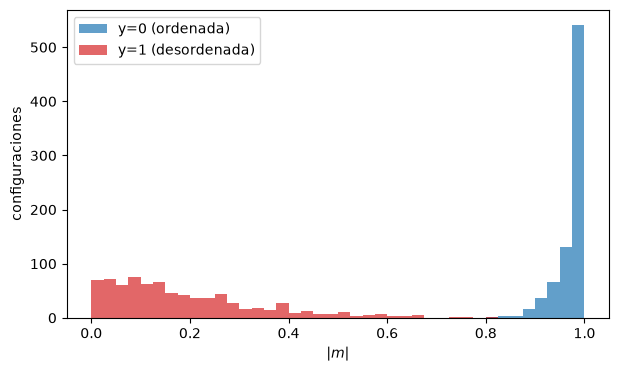

|m| clase 0: media=0.975  mín=0.812
|m| clase 1: media=0.191  máx=0.805
Exactitud clasificando solo con |m| < 0.5: 0.971


In [11]:
plt.figure(figsize=(7, 4))
bins = np.linspace(0, 1, 41)
plt.hist(m[y == 0], bins=bins, alpha=0.7, label="y=0 (ordenada)", color="tab:blue")
plt.hist(m[y == 1], bins=bins, alpha=0.7, label="y=1 (desordenada)", color="tab:red")
plt.xlabel("$|m|$"); plt.ylabel("configuraciones"); plt.legend(); plt.show()

print(f"|m| clase 0: media={m[y==0].mean():.3f}  mín={m[y==0].min():.3f}")
print(f"|m| clase 1: media={m[y==1].mean():.3f}  máx={m[y==1].max():.3f}")

# Umbral simple: ¿qué tan separables son solo con |m|?
umbral = 0.5
acc = ((m < umbral).astype(int) == y).mean()
print(f"Exactitud clasificando solo con |m| < {umbral}: {acc:.3f}")

1. **Temperaturas.** La clase `y=0` (ordenada) corresponde a las temperaturas bajas, hasta T = 1.9. La clase `y=1` (desordenada) corresponde a las altas, desde T = 2.6. El **hueco** es el intervalo 1.9 < T < 2.6, que contiene a T_c ≈ 2.269. Ninguna configuración de entrenamiento viene de esa región, así que el clasificador nunca ve la zona crítica y debe extrapolar hacia ella.
2. **Balance.** El problema está perfectamente balanceado: 800 configuraciones por clase (50 % y 50 %). La exactitud es una métrica válida aquí (a diferencia del caso de púlsares) y el clasificador trivial solo obtiene 50 %.
3. **Histograma de |m|.** Las dos fases se separan bien. La ordenada se concentra en |m| ≈ 0.9–1.0, con un pico marcado en 1. La desordenada se reparte entre |m| = 0 y ≈ 0.65, con una cola hacia valores altos debido a los efectos de tamaño finito (L = 16) y a que T = 2.6 está cerca de T_c. Entre ≈ 0.65 y ≈ 0.85 casi no hay datos, así que un umbral en |m| (por ejemplo 0.75) separa las clases casi sin errores. |m| es el parámetro de orden "obvio" y la red debería aprender algo equivalente.

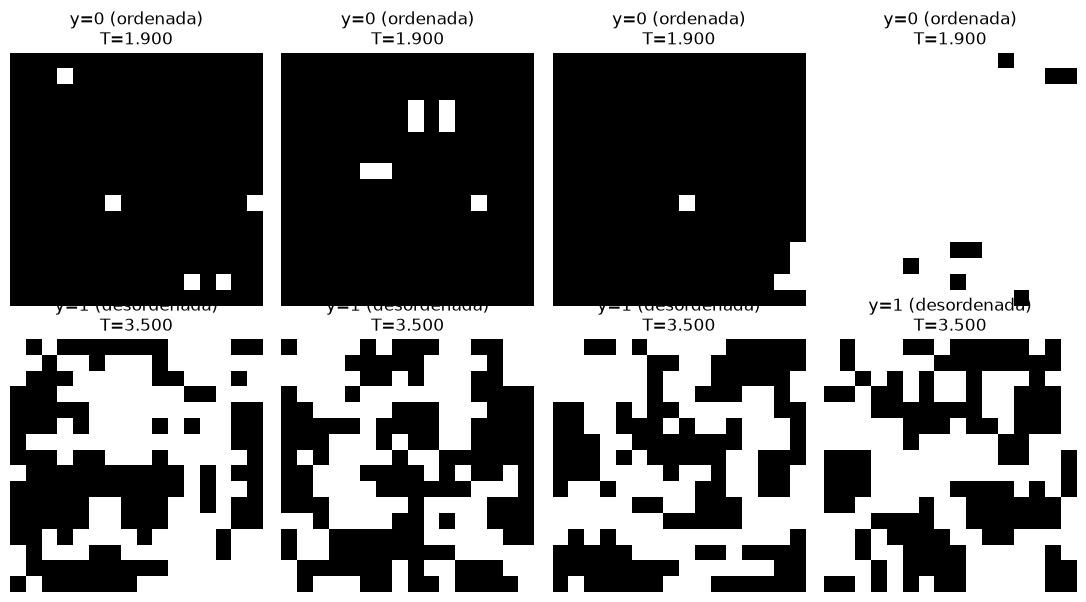

In [13]:
# Configuraciones típicas a T baja y T alta
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for row, (cls, titulo) in enumerate([(0, "ordenada"), (1, "desordenada")]):
    idx = np.where(y == cls)[0][:4]
    for k, i in enumerate(idx):
        axes[row, k].imshow(X[i], cmap="gray", vmin=-1, vmax=1)
        axes[row, k].set_title(f"y={cls} ({titulo})\nT={T[i]:.3f}")
        axes[row, k].axis("off")
plt.tight_layout()
plt.show()

## 4. Partición de los datos: por **realización**

Las configuraciones de una misma cadena Monte Carlo (`realizacion`) están **correlacionadas**
temporalmente. Si mezcláramos al azar, configuraciones casi idénticas caerían en *train* y en
*test* a la vez → fuga de información y métricas infladas.

Partimos por realización:

- **Entrenamiento:** realizaciones `0` y `1`
- **Validación:** realización `2`
- **Prueba:** realización `3`

Además aplanamos cada configuración $16\times16 \to 256$ porque `MLPClassifier` espera
vectores de características.

### Ejercicio 2 — Construir los conjuntos

Completa las máscaras y los arreglos aplanados. Deberías obtener
`X_train (800, 256)`, `X_val (400, 256)` y `X_test (400, 256)`.

In [14]:
# --- Ejercicio 2  ---
mask_train = np.isin(realizacion, [0, 1])
mask_val   = realizacion == 2
mask_test  = realizacion == 3

def aplanar(A):
    return A.reshape(A.shape[0], L * L)

X_train, y_train, T_train = aplanar(X[mask_train]), y[mask_train], T[mask_train]
X_val,   y_val,   T_val   = aplanar(X[mask_val]),   y[mask_val],   T[mask_val]
X_test,  y_test,  T_test  = aplanar(X[mask_test]),  y[mask_test],  T[mask_test]

for nombre, Xs, ys in [("train", X_train, y_train),
                       ("val",   X_val,   y_val),
                       ("test",  X_test,  y_test)]:
    print(f"{nombre:5s}  X={Xs.shape}  y={ys.shape}  clases={np.bincount(ys)}")

train  X=(800, 256)  y=(800,)  clases=[400 400]
val    X=(400, 256)  y=(400,)  clases=[200 200]
test   X=(400, 256)  y=(400,)  clases=[200 200]


## 5. Entrenar el `MLPClassifier`

| Argumento | Valor | Qué controla |
|---|---|---|
| `hidden_layer_sizes=(16, 8, 4)` | 3 capas ocultas | Arquitectura: 256 → 16 → 8 → 4 → 2 |
| `activation="relu"` | ReLU | No linealidad de las capas ocultas |
| `solver="adam"` | Adam | Optimizador basado en gradiente estocástico |
| `learning_rate_init=0.001` | 0.001 | Tamaño de paso inicial |
| `max_iter=1000` | 1000 | Máximo de épocas (puede parar antes por tolerancia) |
| `random_state=42` | 42 | Reproducibilidad (init de pesos y *shuffling*) |

> La capa de salida (2 neuronas, *softmax*) y la pérdida (*log-loss*) las añade `scikit-learn`
> automáticamente al ver que `y` tiene dos clases enteras. En `NN_Cero.ipynb` esto era la
> `sigmoide` final + `cost_Function`; en PyTorch era `nn.Linear(..., 1)` + `BCEWithLogitsLoss`.

### Ejercicio 3 — Instanciar, entrenar y evaluar

1. Crea el modelo con los hiperparámetros de la tabla y ajústalo con `X_train, y_train`.
2. Reporta *accuracy* en train / val / test con `.score(...)`.
3. Grafica `model.loss_curve_` (la pérdida por época que `scikit-learn` guarda).

iteraciones: 675   log-loss final: 0.0453
accuracy train: 1.0000
accuracy val  : 0.9850
accuracy test : 0.9875


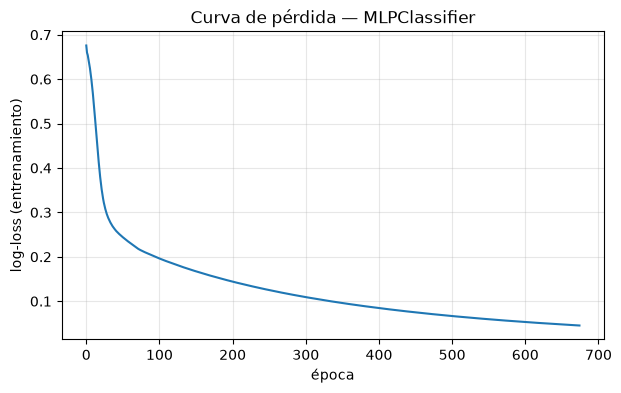

In [15]:
# --- Ejercicio 3  ---
model = MLPClassifier(
    hidden_layer_sizes=(16, 8, 4),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=RNG,
)
model.fit(X_train, y_train)

acc = {
    "train": model.score(X_train, y_train),
    "val":   model.score(X_val,   y_val),
    "test":  model.score(X_test,  y_test),
}
print(f"iteraciones: {model.n_iter_}   log-loss final: {model.loss_:.4f}")
for k, v in acc.items():
    print(f"accuracy {k:5s}: {v:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(model.loss_curve_)
plt.xlabel("época")
plt.ylabel("log-loss (entrenamiento)")
plt.title("Curva de pérdida — MLPClassifier")
plt.grid(alpha=0.3)
plt.show()

### Reflexión (sección 5)

- El *accuracy* de entrenamiento suele ser `1.0000`. ¿Es esto sobreajuste preocupante, dado que
  train / val / test dan valores parecidos? ¿Por qué este problema es "fácil" **lejos** de $T_c$?

No. El sobreajuste se diagnostica por la **brecha** entre entrenamiento y datos no vistos, y aquí es mínima: 1.000 en train frente a 0.985 en validación y 0.9875 en prueba, es decir, ≈1.3 puntos. Además, val y test vienen de realizaciones Monte Carlo **distintas** a las de entrenamiento (2 y 3 frente a 0 y 1), por lo que la partición evita la fuga por correlación temporal y el 98.5-98.75 % es una estimación honesta de la generalización. La curva de pérdida baja de forma suave y monótona hasta ≈0.045, sin saltos ni inestabilidad.

Esa pequeña brecha (≈1.3 puntos, unas 5-6 configuraciones mal clasificadas de 400) probablemente viene de las configuraciones de T = 2.6, que están cerca de T_c y tienen |m| alto, como se vio en el histograma. Con solo 400 muestras por conjunto cada error vale 0.25 puntos, así que la diferencia entre val y test (0.985 vs 0.9875) no es significativa.

**¿Por qué el problema es fácil lejos de T_c?** Porque las dos fases son estructuralmente muy distintas: la ordenada tiene casi todos los espines alineados (|m| ≈ 1) y la desordenada tiene espines casi aleatorios (|m| pequeño). En el histograma de |m| las clases quedan separadas por una región casi vacía (≈0.65 a 0.85), y el hueco de temperaturas (1.9 < T < 2.6) elimina justo los casos ambiguos. Una función casi lineal en la suma de espines ya separa las clases, así que una red pequeña la aprende sin dificultad.

- ¿Qué esperas que ocurra con las probabilidades del modelo **cerca** de $T_c$, donde no vio datos?


La red debe **extrapolar** una frontera aprendida lejos de la transición. Espero que:

- Por debajo de T_c (T ≈ 1.9 a 2.2) las probabilidades P(y=1 | X) sean bajas, y por encima de T_c (T ≈ 2.4 a 2.6) sean altas.
- Al acercarse a T_c el promedio ⟨P(y=1 | X)⟩ pase de forma **gradual** de ≈0 a ≈1, en lugar de dar un salto brusco. Como en T_c las configuraciones tienen magnetización intermedia y fluctuaciones grandes, algunas parecerán ordenadas y otras desordenadas, y la red dará probabilidades intermedias.
- El cruce ⟨P⟩ = 0.5 quede cerca de T_c ≈ 2.269. Esa es la idea de Carrasquilla y Melko: la salida de la red actúa como un parámetro de orden efectivo.

Hay que tener presente que la red **nunca fue entrenada** en esa región, así que no hay garantía de calibración: las probabilidades intermedias son una consecuencia de la extrapolación y no una medida calibrada. Además, con L = 16 los efectos de tamaño finito suavizan y pueden desplazar el cruce respecto al valor de Onsager.

## 6. El clasificador como termómetro

Para una configuración $X$, `model.predict_proba(X)[:, 1]` es $P(y{=}1\mid X)$: la "confianza"
del modelo en que la configuración pertenece a la **fase desordenada**.

Promediando sobre muchas configuraciones a temperatura fija $T$ obtenemos una curva
$\langle P(y{=}1\mid X)\rangle(T)$ que va de $\approx 0$ (ordenado) a $\approx 1$ (desordenado).
Definimos la estimación de $T_c$ como la temperatura del **cruce por 0.5**.

## 7. Datos de barrido fino alrededor de $T_c$

`temperatura_critica.npz` contiene **6200** configuraciones $16\times16$ en **31 temperaturas**
entre 1.6 y 3.2 (más densas cerca de $T_c$), con 4 realizaciones. **No trae etiquetas de
entrenamiento:** solo `y_ref`, una etiqueta obtenida aplicando el $T_c$ exacto, que usaremos
**únicamente para verificar** (usarla para entrenar sería hacer trampa).

In [17]:
datos_tc = np.load("/workspaces/005_CCA_Estudiantes/Laboratorios/Datos/temperatura_critica.npz", allow_pickle=False)
X_tc = datos_tc["X"].reshape(datos_tc["X"].shape[0], L * L)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]
y_ref_tc = datos_tc["y_ref"]

print("X_tc:", X_tc.shape)
print("temperaturas:", np.unique(T_tc))

# Probabilidad de la clase "desordenada" (y = 1)
idx1 = list(model.classes_).index(1)
p1_tc = model.predict_proba(X_tc)[:, idx1]

# Chequeo con y_ref (NO usar para entrenar)
pred_tc = (p1_tc >= 0.5).astype(int)
print("accuracy vs y_ref (solo verificacion):",
      round((pred_tc == y_ref_tc).mean(), 4))

X_tc: (6200, 256)
temperaturas: [1.6   1.7   1.8   1.9   2.    2.05  2.075 2.1   2.125 2.15  2.175 2.2
 2.225 2.25  2.275 2.3   2.325 2.35  2.375 2.4   2.425 2.45  2.475 2.5
 2.6   2.7   2.8   2.9   3.    3.1   3.2  ]
accuracy vs y_ref (solo verificacion): 0.8247


### Ejercicio 4 — Curva $\langle P\rangle$ vs $T$

Construye un `DataFrame` con columnas `T, realizacion, prob` y agrégalo por
`(realizacion, T)` para obtener la media y la desviación de `prob`. Grafica una curva por
realización y marca la línea $P = 0.5$.

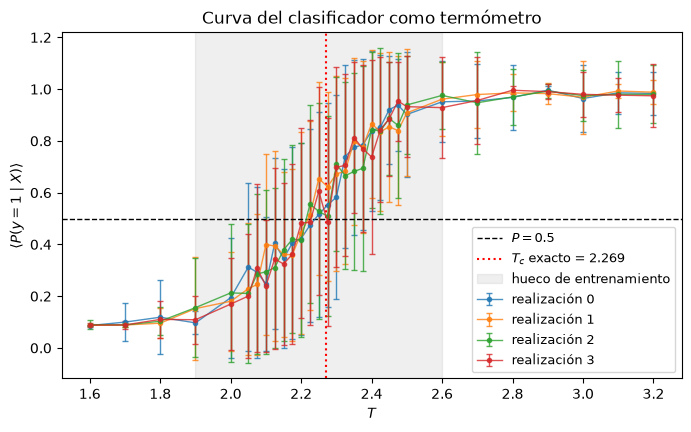

In [19]:
# --- Ejercicio 4 ---
df = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": p1_tc})

resumen = (df.groupby(["realizacion", "T"])
             .agg(prob_media=("prob", "mean"),
                  prob_std=("prob", "std"),
                  N=("prob", "size"))
             .reset_index())

# Realizar el grafico
plt.figure(figsize=(8, 4.5))
for r in sorted(resumen["realizacion"].unique()):
    s = resumen[resumen["realizacion"] == r]
    plt.errorbar(s["T"], s["prob_media"], yerr=s["prob_std"],
                 fmt="o-", ms=3, lw=1, capsize=2, alpha=0.8,
                 label=f"realización {r}")

plt.axhline(0.5, color="k", ls="--", lw=1, label=r"$P=0.5$")
plt.axvline(Tc_exacto, color="r", ls=":", lw=1.5, label=f"$T_c$ exacto = {Tc_exacto:.3f}")
plt.axvspan(1.9, 2.6, color="gray", alpha=0.12, label="hueco de entrenamiento")
plt.xlabel("$T$"); plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.title("Curva del clasificador como termómetro")
plt.legend(fontsize=9); plt.show()

### Ejercicio 5 — Estimar $T_c$ por interpolación

Para cada realización, encuentra el primer par de temperaturas consecutivas donde
$\langle P\rangle$ cruza 0.5 e interpola linealmente:

$$T_c \approx T_i + (0.5 - P_i)\,\frac{T_{i+1}-T_i}{P_{i+1}-P_i}.$$

Luego promedia entre realizaciones y reporta la media, la desviación estándar y el error
estándar de la media (SEM).

In [20]:
# --- Ejercicio 5  ---
def cruce_05(temps, probs):
    temps, probs = np.asarray(temps), np.asarray(probs)
    for i in range(len(temps) - 1):
        if (probs[i] - 0.5) * (probs[i + 1] - 0.5) <= 0 and probs[i + 1] != probs[i]:
            return (temps[i] + (0.5 - probs[i]) *
                    (temps[i + 1] - temps[i]) / (probs[i + 1] - probs[i]))
    return np.nan

Tc_por_realizacion = []
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    Tc_r = cruce_05(d["T"].to_numpy(), d["prob_media"].to_numpy())
    Tc_por_realizacion.append(Tc_r)
    print(f"realización {r}:  Tc = {Tc_r:.4f}")

Tc_por_realizacion = np.array(Tc_por_realizacion)
Tc_est = np.nanmean(Tc_por_realizacion)
Tc_std = np.nanstd(Tc_por_realizacion, ddof=1)
Tc_sem = Tc_std / np.sqrt(np.sum(~np.isnan(Tc_por_realizacion)))

print("\n" + "-" * 44)
print(f"Tc estimado    = {Tc_est:.4f} +/- {Tc_sem:.4f} (SEM)")
print(f"Tc Onsager     = {Tc_exacto:.4f}")
print(f"error relativo = {100 * abs(Tc_est - Tc_exacto) / Tc_exacto:.2f} %")

realización 0:  Tc = 2.2403
realización 1:  Tc = 2.2204
realización 2:  Tc = 2.2149
realización 3:  Tc = 2.2280

--------------------------------------------
Tc estimado    = 2.2259 +/- 0.0055 (SEM)
Tc Onsager     = 2.2692
error relativo = 1.91 %


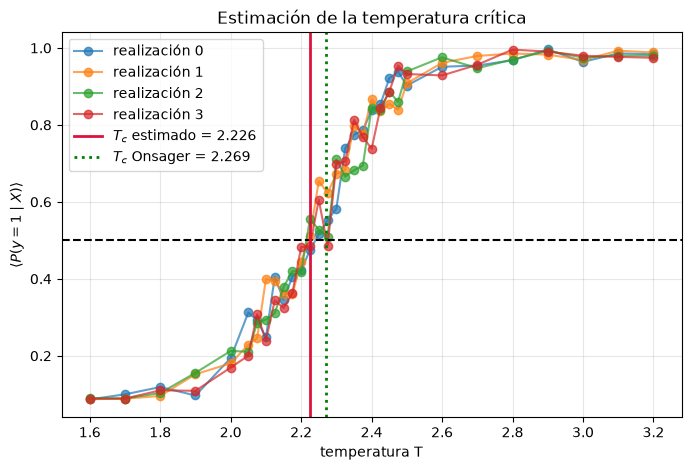

In [21]:
plt.figure(figsize=(8, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.plot(d["T"], d["prob_media"], "o-", alpha=0.7, label=f"realización {r}")
plt.axhline(0.5, ls="--", color="k")
plt.axvline(Tc_est, ls="-", color="crimson", lw=2,
            label=fr"$T_c$ estimado = {Tc_est:.3f}")
plt.axvline(Tc_exacto, ls=":", color="green", lw=2,
            label=fr"$T_c$ Onsager = {Tc_exacto:.3f}")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.title("Estimación de la temperatura crítica")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Análisis crítico

Responde en celdas de texto, con evidencia (números o gráficas de tu notebook):

1. **Sesgo del estimador.** El $T_c$ estimado suele quedar *por debajo* de Onsager
   ($\approx 2.23$ vs $2.269$). Menciona al menos dos causas: tamaño finito $L=16$, definición
   de la etiqueta `y`, rango de temperaturas de entrenamiento, uso del umbral fijo 0.5.
2. **Arquitectura.** Repite el pipeline con `hidden_layer_sizes=(64,)` y con `(32, 16, 8)`.
   ¿Cambia $T_c$? ¿Cambia la *pendiente* de la curva en la transición?
3. **Reproducibilidad.** Entrena con 5 semillas distintas (`random_state`) y reporta
   $T_c$ media ± desviación. ¿La dispersión por semilla es mayor o menor que la dispersión
   entre realizaciones?
4. **Definición alternativa.** Usa la *fracción de configuraciones clasificadas como fase 1*
   (`pred.mean()` por $T$) en vez de `prob_media`. ¿Obtienes el mismo $T_c$?
5. **Estandarización.** Los espines ya están en $\{-1,+1\}$. ¿Ayuda un `StandardScaler`?
   ¿Por qué sí o por qué no en este problema?

In [23]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def estimar_Tc(modelo, usar_fraccion=False):
    modelo.fit(X_train, y_train)
    p1 = modelo.predict_proba(X_tc)[:, list(modelo.classes_).index(1)]
    val = (p1 >= 0.5).astype(float) if usar_fraccion else p1
    d = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "v": val})
    res = d.groupby(["realizacion", "T"])["v"].mean().reset_index()

    Tcs = []
    for r in np.unique(realizacion_tc):
        s = res[res.realizacion == r].sort_values("T")
        Tcs.append(cruce_05(s["T"].to_numpy(), s["v"].to_numpy()))
    Tcs = np.array(Tcs)

    # curva media entre realizaciones y pendiente en el cruce
    curva = res.groupby("T")["v"].mean()
    Tc_m = np.nanmean(Tcs)
    pend = np.interp(Tc_m, curva.index, np.gradient(curva.values, curva.index.values))
    return Tcs, curva, pend

def mlp(capas, seed=RNG):
    return MLPClassifier(hidden_layer_sizes=capas, activation="relu", solver="adam",
                         learning_rate_init=0.001, max_iter=1000, random_state=seed)

**1. Sesgo del estimador.** Con (16, 8, 4) el Tc queda por debajo de Onsager (≈ 8 SEM), pero con otras arquitecturas queda por encima (pregunta 2), así que el sesgo no es un efecto físico universal. Causas que pueden contribuir: el tamaño finito (L = 16), que redondea la transición y desplaza el Tc efectivo; la ausencia de datos de entrenamiento en el hueco 1.9 < T < 2.6, donde la frontera es una extrapolación; el umbral fijo 0.5, que no es una probabilidad calibrada porque la red nunca vio esa región; y que la etiqueta y se asigna por temperatura y no por la fase efectiva de cada configuración.

(16, 8, 4)    Tc = 2.2259 ± 0.0055   pendiente en Tc = 2.61
(64,)         Tc = 2.3736 ± 0.0132   pendiente en Tc = 2.52
(32, 16, 8)   Tc = 2.3652 ± 0.0066   pendiente en Tc = 2.99


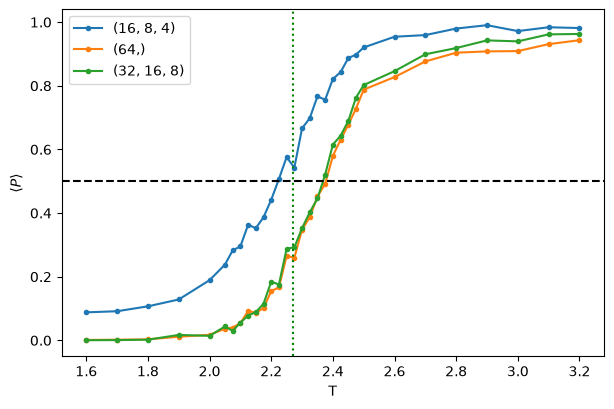

In [ ]:
#pregunta 2
plt.figure(figsize=(7, 4.5))
for capas in [(16, 8, 4), (64,), (32, 16, 8)]:
    Tcs, curva, pend = estimar_Tc(mlp(capas))
    print(f"{str(capas):12}  Tc = {Tcs.mean():.4f} ± {Tcs.std(ddof=1)/2:.4f}   pendiente en Tc = {pend:.2f}")
    plt.plot(curva.index, curva.values, "o-", ms=3, label=str(capas))
plt.axhline(0.5, color="k", ls="--"); plt.axvline(Tc_exacto, color="g", ls=":")
plt.xlabel("T"); plt.ylabel(r"$\langle P\rangle$"); plt.legend(); plt.show()

**2. Arquitectura.** Sí cambia Tc, y mucho más de lo esperado:

| Arquitectura | Tc | Pendiente en Tc |
|---|---|---|
| (16, 8, 4) | 2.226 ± 0.006 | 2.61 |
| (64,) | 2.374 ± 0.013 | 2.52 |
| (32, 16, 8) | 2.365 ± 0.007 | 2.99 |

La variación entre arquitecturas (≈ 0.15) es mucho mayor que el SEM entre realizaciones (≈ 0.006-0.013), así que ese SEM no representa la incertidumbre total del método. Además, el signo del error respecto a Onsager cambia: (16, 8, 4) queda por debajo (−0.043) y las otras dos por encima (≈ +0.10). Por tanto, el sesgo no es una propiedad física fija del método, sino que depende de cómo cada red extrapola dentro del hueco de entrenamiento, donde no vio datos. La pendiente en Tc varía poco (2.5-3.0) y sin relación clara con el tamaño de la red. Con una sola semilla por arquitectura no se puede separar el efecto de la arquitectura del de la inicialización (ver pregunta 3).

La diferencia aparente se debe en buena parte a la semilla: con (16, 8, 4) otras cuatro semillas dan ≈ 2.36, igual que las otras dos arquitecturas (pregunta 3). La pendiente en Tc varía poco (2.5-3.0) y sin tendencia con el tamaño. Con estos datos no hay evidencia clara de que la arquitectura cambie Tc; para afirmarlo habría que repetir cada arquitectura con varias semillas.

In [ ]:
#pregunta 3
Tc_semillas = []
for s in [0, 1, 2, 3, 4]:
    Tcs, _, _ = estimar_Tc(mlp((16, 8, 4), seed=s))
    Tc_semillas.append(Tcs.mean())
    print(f"semilla {s}: Tc = {Tcs.mean():.4f}   (std entre realizaciones = {Tcs.std(ddof=1):.4f})")

Tc_semillas = np.array(Tc_semillas)
print(f"\nPor semilla: Tc = {Tc_semillas.mean():.4f} ± {Tc_semillas.std(ddof=1):.4f}")
print(f"Entre realizaciones (semilla 42): {Tc_por_realizacion.std(ddof=1):.4f}")

semilla 0: Tc = 2.3578   (std entre realizaciones = 0.0147)
semilla 1: Tc = 2.3633   (std entre realizaciones = 0.0223)
semilla 2: Tc = 2.3619   (std entre realizaciones = 0.0217)
semilla 3: Tc = 2.2767   (std entre realizaciones = 0.0290)
semilla 4: Tc = 2.3583   (std entre realizaciones = 0.0227)

Por semilla: Tc = 2.3436 ± 0.0375
Entre realizaciones (semilla 42): 0.0110


**3. Reproducibilidad.** Con (16, 8, 4) y cinco semillas, Tc = 2.344 ± 0.038 (media ± desviación; mediana ≈ 2.358). Cuatro semillas dan Tc ≈ 2.36 (rango 2.358-2.363), una da 2.277 y la semilla original (42) dio 2.226. La dispersión por semilla (0.038) es unas 3.4 veces mayor que la dispersión entre realizaciones Monte Carlo (0.011), así que el SEM de 0.0055 reportado en el Ejercicio 5 subestima la incertidumbre total: gran parte proviene de la inicialización de la red y no de los datos. La distribución es asimétrica (un grupo apretado más dos valores bajos), por lo que la media ± desviación resume mal; conviene reportar también la mediana y los valores individuales. Una estimación honesta sería Tc ≈ 2.34 ± 0.04, en la que Onsager (2.269) queda a ≈ 2 desviaciones, y no el 2.226 ± 0.006 de una sola semilla.

In [26]:
#pregunta 4
Tcs_p, _, _ = estimar_Tc(mlp((16, 8, 4)))
Tcs_f, _, _ = estimar_Tc(mlp((16, 8, 4)), usar_fraccion=True)
print(f"prob_media : Tc = {Tcs_p.mean():.4f} ± {Tcs_p.std(ddof=1)/2:.4f}")
print(f"fracción   : Tc = {Tcs_f.mean():.4f} ± {Tcs_f.std(ddof=1)/2:.4f}")

prob_media : Tc = 2.2259 ± 0.0055
fracción   : Tc = 2.2331 ± 0.0067


**4. Definición alternativa.** Con la semilla 42, la fracción de configuraciones clasificadas como fase 1 da Tc = 2.233 ± 0.007, frente a 2.226 ± 0.006 con ⟨P⟩. La diferencia (≈ 0.007) es de aproximadamente 1 SEM combinado, por lo que no es significativa, y es mucho menor que la dispersión por semilla (≈ 0.04). Ambas definiciones son versiones del mismo cruce (la fracción es una versión "dura" de ⟨P⟩) y coinciden cuando la distribución de P a cada T es aproximadamente simétrica alrededor del cruce. En este problema la definición del observable influye mucho menos que la inicialización de la red.

In [27]:
#pregunta 5
Tcs_s, curva_s, pend_s = estimar_Tc(make_pipeline(StandardScaler(), mlp((16, 8, 4))))
print(f"con StandardScaler: Tc = {Tcs_s.mean():.4f}   pendiente = {pend_s:.2f}")
print(f"sin escalar       : Tc = {Tcs_p.mean():.4f}")

esc = StandardScaler().fit(X_train)
print("media de las columnas (rango):", esc.mean_.min().round(3), esc.mean_.max().round(3))
print("std de las columnas (rango)  :", esc.scale_.min().round(3), esc.scale_.max().round(3))

con StandardScaler: Tc = 2.2076   pendiente = 2.53
sin escalar       : Tc = 2.2259
media de las columnas (rango): -0.038 0.125
std de las columnas (rango)  : 0.992 1.0


**5. Estandarización.** No ayuda de forma apreciable. Los espines ya valen ±1, y en el conjunto de entrenamiento las columnas tienen media entre −0.04 y 0.13 y desviación entre 0.992 y 1.000, por lo que el `StandardScaler` aplica una transformación casi idéntica. Con la semilla 42 el Tc pasó de 2.226 a 2.208 y la pendiente de 2.61 a 2.53. Esa diferencia (≈ 0.02) es menor que la dispersión por semilla (≈ 0.04), así que no puede atribuirse al escalado. El escalamiento es importante cuando las características tienen escalas muy distintas (como en la Parte 4 del laboratorio anterior), pero aquí todas las entradas comparten la misma escala y el mismo rango de valores.

## 9. Reto  — Escalamiento con el tamaño del sistema

Con el programa de ising generar varias datos para diferentes tipo de redes L=10x10, L=15x15, L=20x20, L=25x25, L=30x30

1. Construye un conjunto de entrenamiento.
2. Entrena un nuevo `MLPClassifier`, repite los Ejercicios 4–5 y obtén $T_c(L=20)$.
3. Compara todas las $T_c$ ¿La estimación se acerca a Onsager al crecer $L$?
   Relaciónalo con el *finite-size scaling*.

L=10  Tc = 2.0492 ± 0.0019  (mediana 2.0499)  acc_val=0.968
L=15  Tc = 2.1310 ± 0.0015  (mediana 2.1316)  acc_val=0.992
L=20  Tc = 2.1981 ± 0.0046  (mediana 2.1987)  acc_val=0.986
L=25  Tc = 2.2491 ± 0.0024  (mediana 2.2482)  acc_val=0.986
L=30  Tc = 2.2566 ± 0.0031  (mediana 2.2574)  acc_val=0.984
 L  Tc_media  Tc_mediana  std_semillas  acc_val  dif_Onsager
10    2.0492      2.0499        0.0019   0.9676      -0.2200
15    2.1310      2.1316        0.0015   0.9916      -0.1382
20    2.1981      2.1987        0.0046   0.9864      -0.0711
25    2.2491      2.2482        0.0024   0.9864      -0.0201
30    2.2566      2.2574        0.0031   0.9836      -0.0126

Extrapolación L→∞: Tc_inf = 2.3649  (Onsager 2.2692),  a = -3.244


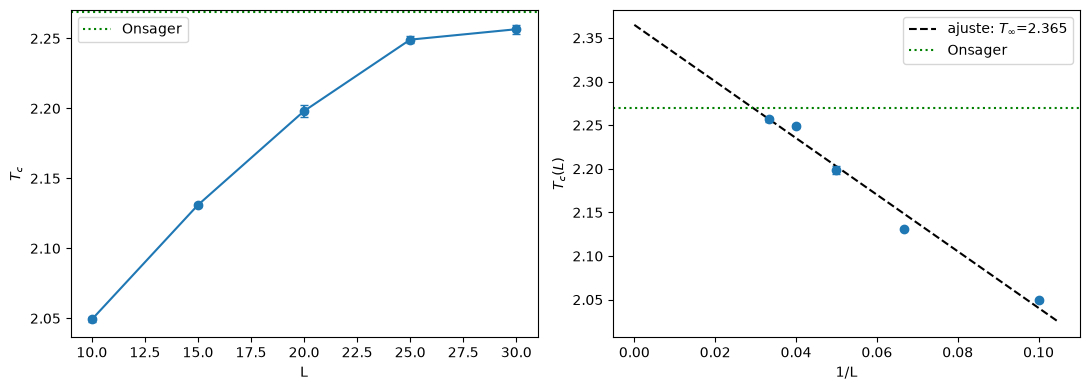

In [28]:
# Reto (opcional): esqueleto para L = 20
# ---------- Temperaturas (las mismas del laboratorio) ----------
T_ord  = [1.2, 1.375, 1.55, 1.725, 1.9]
T_des  = [2.6, 2.825, 3.05, 3.275, 3.5]
T_barr = [1.6, 1.7, 1.8, 1.9, 2.0, 2.05, 2.075, 2.1, 2.125, 2.15, 2.175, 2.2, 2.225,
          2.25, 2.275, 2.3, 2.325, 2.35, 2.375, 2.4, 2.425, 2.45, 2.475, 2.5,
          2.6, 2.7, 2.8, 2.9, 3.0, 3.1, 3.2]

# ---------- Simulador Metropolis vectorizado ----------
def colores(L):
    """Coloración greedy del toro LxL: sitios del mismo color no son vecinos."""
    col = -np.ones((L, L), dtype=int)
    for i in range(L):
        for j in range(L):
            vec = {col[(i+1) % L, j], col[(i-1) % L, j], col[i, (j+1) % L], col[i, (j-1) % L]}
            c = 0
            while c in vec:
                c += 1
            col[i, j] = c
    return col

def simular(L, temps, n_snap, seed, termal=1000, espaciado=10):
    """4 realizaciones x len(temps) cadenas en paralelo. Devuelve X (N,L,L), T (N,), realización (N,)."""
    rng = np.random.default_rng(seed)
    masks = [colores(L) == c for c in range(colores(L).max() + 1)]
    Tch = np.tile(np.array(temps, float), 4)                  # temperatura de cada cadena
    real = np.repeat(np.arange(4), len(temps))                # realización de cada cadena
    beta = (1.0 / Tch)[:, None, None]
    s = np.where(Tch[:, None, None] < Tc_exacto, 1,           # T<Tc: arranque ordenado
                 rng.choice([-1, 1], size=(len(Tch), L, L))).astype(np.int8)

    def barrido():
        for m in masks:
            nn = np.roll(s, 1, 1) + np.roll(s, -1, 1) + np.roll(s, 1, 2) + np.roll(s, -1, 2)
            dE = 2 * s * nn
            acepta = (dE <= 0) | (rng.random(s.shape) < np.exp(-beta * dE))
            s[acepta & m] *= -1

    for _ in range(termal):
        barrido()
    muestras = []
    for _ in range(n_snap):
        for _ in range(espaciado):
            barrido()
        muestras.append(s.copy())
    return np.concatenate(muestras), np.tile(Tch, n_snap), np.tile(real, n_snap)

# ---------- Pipeline para un L: datos -> MLP (16,8,4) -> Tc por cruce de 0.5 ----------
def tc_para_L(L, seeds=range(5)):
    Xa, Ta, Ra = simular(L, T_ord + T_des, 50, seed=L)            # entrenamiento (lejos de Tc)
    Xb, Tb, Rb = simular(L, T_barr,        50, seed=1000 + L)     # barrido fino
    ya = (Ta > Tc_exacto).astype(int)                             # 0 ordenada, 1 desordenada
    Xa, Xb = Xa.reshape(len(Xa), -1), Xb.reshape(len(Xb), -1)
    tr, va = Ra < 2, Ra == 2                                      # train: realiz. 0,1 | val: 2

    Tcs, accs = [], []
    for sd in seeds:
        clf = MLPClassifier(hidden_layer_sizes=(16, 8, 4), activation="relu", solver="adam",
                            learning_rate_init=0.001, max_iter=1000, random_state=sd)
        clf.fit(Xa[tr], ya[tr])
        accs.append(clf.score(Xa[va], ya[va]))
        p1 = clf.predict_proba(Xb)[:, list(clf.classes_).index(1)]
        d = pd.DataFrame({"T": Tb, "r": Rb, "p": p1}).groupby(["r", "T"])["p"].mean().reset_index()
        Tcs.append(np.nanmean([cruce_05(g["T"].to_numpy(), g["p"].to_numpy())
                               for _, g in d.sort_values("T").groupby("r")]))
    return np.array(Tcs), np.mean(accs)

# ---------- Barrido en L ----------
filas = []
for L in [10, 15, 20, 25, 30]:
    Tcs, acc = tc_para_L(L)
    filas.append(dict(L=L, Tc_media=Tcs.mean(), Tc_mediana=np.median(Tcs),
                      std_semillas=Tcs.std(ddof=1), acc_val=acc))
    print(f"L={L:2d}  Tc = {Tcs.mean():.4f} ± {Tcs.std(ddof=1):.4f}  "
          f"(mediana {np.median(Tcs):.4f})  acc_val={acc:.3f}")

res = pd.DataFrame(filas)
res["dif_Onsager"] = res["Tc_media"] - Tc_exacto
print(res.round(4).to_string(index=False))

# ---------- Finite-size scaling: Tc(L) = Tc_inf + a/L  (nu = 1) ----------
x = 1 / res["L"].to_numpy()
a, Tinf = np.polyfit(x, res["Tc_media"].to_numpy(), 1)
print(f"\nExtrapolación L→∞: Tc_inf = {Tinf:.4f}  (Onsager {Tc_exacto:.4f}),  a = {a:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].errorbar(res["L"], res["Tc_media"], yerr=res["std_semillas"], fmt="o-", capsize=3)
ax[0].axhline(Tc_exacto, color="g", ls=":", label="Onsager")
ax[0].set_xlabel("L"); ax[0].set_ylabel("$T_c$"); ax[0].legend()
xx = np.linspace(0, x.max() * 1.05, 50)
ax[1].errorbar(x, res["Tc_media"], yerr=res["std_semillas"], fmt="o", capsize=3)
ax[1].plot(xx, Tinf + a * xx, "k--", label=f"ajuste: $T_\\infty$={Tinf:.3f}")
ax[1].axhline(Tc_exacto, color="g", ls=":", label="Onsager")
ax[1].set_xlabel("1/L"); ax[1].set_ylabel("$T_c(L)$"); ax[1].legend()
plt.tight_layout(); plt.show()

In [30]:
from scipy.optimize import curve_fit

f = lambda L, Tinf, a, e: Tinf + a * L**(-e)
p, cov = curve_fit(f, res["L"], res["Tc_media"], p0=[2.27, -3, 1], maxfev=10000)
print(f"T_inf = {p[0]:.4f}   a = {p[1]:.3f}   exponente = {p[2]:.3f}   (nu=1 -> exponente 1)")

# Solo L >= 20
m = res["L"] >= 20
a2, T2 = np.polyfit(1/res["L"][m], res["Tc_media"][m], 1)
print(f"Ajuste lineal con L>=20: T_inf = {T2:.4f}")

T_inf = 2.6385   a = -1.559   exponente = 0.421   (nu=1 -> exponente 1)
Ajuste lineal con L>=20: T_inf = 2.3840


### Reto — Escalamiento con L

| L | Tc(L) | std (5 semillas) | Tc − Tc_Onsager |
|---|---|---|---|
| 10 | 2.049 | 0.002 | −0.220 |
| 15 | 2.131 | 0.002 | −0.138 |
| 20 | 2.198 | 0.005 | −0.071 |
| 25 | 2.249 | 0.002 | −0.020 |
| 30 | 2.257 | 0.003 | −0.013 |

**Resultado:** Tc(L = 20) = 2.198 ± 0.005.

**Tendencia.** Tc(L) crece de forma monótona hacia el valor de Onsager (2.269) y siempre queda por debajo de él. El error baja de −0.22 (L = 10) a −0.013 (L = 30). Los cambios entre tamaños consecutivos son mucho mayores que la dispersión por semilla, así que la tendencia no es ruido. Esto es lo esperado por *finite-size scaling*: en sistemas finitos la transición se redondea y Tc(L) se acerca a Tc(∞) al crecer L.

**Extrapolación.** La ley esperada es Tc(L) = T∞ + a·L^(−1/ν), con ν = 1. Los ajustes dieron:

| Ajuste | T∞ |
|---|---|
| Lineal en 1/L, L = 10–30 | 2.365 |
| Lineal en 1/L, L ≥ 20 | 2.384 |
| Exponente libre (e = 0.42) | 2.639 |

Los tres sobrepasan a Onsager (2.269), por lo que no se reporta ninguno como estimación de T∞. Los puntos se aplanan en L = 25–30, y en este rango no siguen la ley 1/L. Con solo cinco tamaños, el ajuste con exponente libre está mal condicionado y no sirve para medir ν.

**Limitaciones.** Las barras de error solo recogen la inicialización de la red; hay una única simulación de Monte Carlo por L. Para extrapolar de forma fiable harían falta tamaños mayores y varias simulaciones independientes por L.

**Conclusión.** Sí, la estimación se acerca a Onsager al crecer L, en línea con el *finite-size scaling*, pero con estos datos no se puede dar un valor confiable de Tc(∞).